# Date Fruit Classification: ANN vs Classical Machine Learning

**Goal:** classify date fruit into 7 varieties from 34 image-derived measurements, and find out whether a neural network (ANN) actually beats classical ML algorithms on this dataset.

| | |
|---|---|
| **Task** | Multiclass classification (7 classes) |
| **Data** | 898 samples, 34 numeric features (shape, colour and texture measurements) |
| **Target** | `Class`: BERHI, DEGLET, DOKOL, IRAQI, ROTANA, SAFAVI, SOGAY |
| **Models compared** | Logistic Regression, KNN, Gaussian Naive Bayes, Decision Tree, SVM, Random Forest, Gradient Boosting, XGBoost, **ANN (PyTorch)** |
| **Metrics** | Accuracy and macro F1 (macro F1 matters because the classes are imbalanced) |

## Evaluation protocol

1. Hold out **20 % of the data as a test set** (stratified). It is used once, at the very end.
2. Compare all models with **5-fold stratified cross-validation on the training set**. A single train/test split on 898 rows is too noisy to rank models.
3. Scaling lives **inside each pipeline**, so it is fit on training folds only (no data leakage).
4. The ANN uses an internal validation split with **early stopping**, so it never sees the test data either.

## Contents

1. Setup
2. Load and explore the data
3. Preprocessing and train/test split
4. Models (including the PyTorch ANN)
5. Cross-validation and test results
6. Model comparison plot
7. Error analysis: confusion matrices
8. ANN deep dive: training curves and seed stability
9. Save results
10. Conclusions

## 1. Setup

In [1]:
import os
import random
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

SEED = 42
N_SPLITS = 5
TEST_SIZE = 0.20


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()

In [2]:
# Locate the dataset whether the notebook is run from the repo root or from notebooks/
DATA_FILE = "DateFruit_Dataset.csv"
candidates = [os.path.join("data", DATA_FILE), os.path.join("..", "data", DATA_FILE)]
DATA_PATH = next((p for p in candidates if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError(f"Put {DATA_FILE} inside the data/ folder of this repository.")

ROOT = os.path.dirname(os.path.dirname(DATA_PATH))
RESULTS_DIR = os.path.join(ROOT, "results")
FIG_DIR = os.path.join(RESULTS_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)


def save_fig(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches="tight")

print("Data file :", DATA_PATH)
print("PyTorch   :", torch.__version__)

Data file : ../data/DateFruit_Dataset.csv
PyTorch   : 2.15.0+cu132


## 2. Load and explore the data

In [3]:
df = pd.read_csv(DATA_PATH)
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
display(df.head())

Shape: 898 rows x 35 columns


,AREA,PERIMETER,MAJOR_AXIS,MINOR_AXIS,ECCENTRICITY,EQDIASQ,SOLIDITY,CONVEX_AREA,EXTENT,ASPECT_RATIO,...,KurtosisRR,KurtosisRG,KurtosisRB,EntropyRR,EntropyRG,EntropyRB,ALLdaub4RR,ALLdaub4RG,ALLdaub4RB,Class
0,422163,2378.908,837.8484,645.6693,0.6373,733.1539,0.9947,424428,0.7831,1.2976,...,3.2370,2.9574,4.2287,-59191263232,-50714214400,-39922372608,58.7255,54.9554,47.8400,BERHI
1,338136,2085.144,723.8198,595.2073,0.5690,656.1464,0.9974,339014,0.7795,1.2161,...,2.6228,2.6350,3.1704,-34233065472,-37462601728,-31477794816,50.0259,52.8168,47.8315,BERHI
2,526843,2647.394,940.7379,715.3638,0.6494,819.0222,0.9962,528876,0.7657,1.3150,...,3.7516,3.8611,4.7192,-93948354560,-74738221056,-60311207936,65.4772,59.2860,51.9378,BERHI
3,416063,2351.210,827.9804,645.2988,0.6266,727.8378,0.9948,418255,0.7759,1.2831,...,5.0401,8.6136,8.2618,-32074307584,-32060925952,-29575010304,43.3900,44.1259,41.1882,BERHI
4,347562,2160.354,763.9877,582.8359,0.6465,665.2291,0.9908,350797,0.7569,1.3108,...,2.7016,2.9761,4.4146,-39980974080,-35980042240,-25593278464,52.7743,50.9080,42.6666,BERHI


In [4]:
features = df.drop(columns="Class")
print("Missing values  :", int(df.isnull().sum().sum()))
print("Duplicate rows  :", int(df.duplicated().sum()))
print("Feature dtypes  :", dict(features.dtypes.value_counts().astype(int)))

ranges = (features.max() - features.min()).sort_values()
print(f"\nSmallest feature range: {ranges.index[0]} = {ranges.iloc[0]:.4f}")
print(f"Largest feature range : {ranges.index[-1]} = {ranges.iloc[-1]:,.0f}")
print("Features live on very different scales, so scaling is required for ANN, SVM, KNN and Logistic Regression.")

Missing values  : 0
Duplicate rows  : 0
Feature dtypes  : {dtype('float64'): np.int64(29), dtype('int64'): np.int64(5)}

Smallest feature range: SHAPEFACTOR_2 = 0.0032
Largest feature range : EntropyRR = 108,959,689,104
Features live on very different scales, so scaling is required for ANN, SVM, KNN and Logistic Regression.


,samples
Class,
DOKOL,204
SAFAVI,199
ROTANA,166
DEGLET,98
SOGAY,94
IRAQI,72
BERHI,65


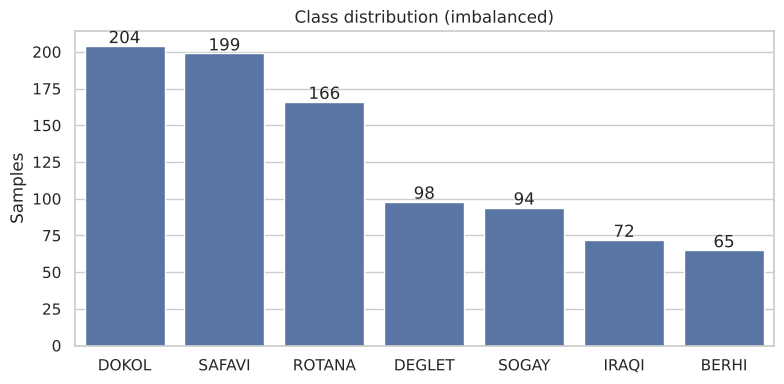

In [5]:
class_counts = df["Class"].value_counts()
display(class_counts.rename("samples").to_frame())

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=class_counts.index, y=class_counts.values, color="#4C72B0", ax=ax)
for i, v in enumerate(class_counts.values):
    ax.text(i, v + 2, str(v), ha="center")
ax.set(title="Class distribution (imbalanced)", xlabel="", ylabel="Samples")
plt.tight_layout()
save_fig("cls_class_distribution.png")
plt.show()

The classes are not balanced (the largest has about 3x the samples of the smallest). That is why the split is **stratified** and why **macro F1** is reported next to accuracy.

## 3. Preprocessing and train/test split

In [6]:
X = df.drop(columns="Class")
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df["Class"])
class_names = list(label_encoder.classes_)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED
)
print(f"Train: {X_train.shape[0]} samples | Test: {X_test.shape[0]} samples")
print("Classes:", dict(enumerate(class_names)))

Train: 718 samples | Test: 180 samples
Classes: {0: 'BERHI', 1: 'DEGLET', 2: 'DOKOL', 3: 'IRAQI', 4: 'ROTANA', 5: 'SAFAVI', 6: 'SOGAY'}


## 4. Models

Every model is wrapped in a scikit-learn `Pipeline`. Models that depend on feature scale get a `StandardScaler` as their first step. Tree-based models do not need scaling.

The ANN is written in **PyTorch** and wrapped in a small scikit-learn-compatible class (`TorchANNClassifier`). This lets it go through exactly the same cross-validation code as every other model, which keeps the comparison fair.

**ANN design:** `34 -> 64 -> 64 -> 7`, ReLU activations, dropout 0.2, Adam optimizer, cross-entropy loss, early stopping on validation loss.

In [7]:
class MLP(nn.Module):
    """Fully connected network: [Linear -> ReLU -> Dropout] x N -> Linear."""

    def __init__(self, in_dim, hidden, out_dim, dropout):
        super().__init__()
        layers, prev = [], in_dim
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, out_dim))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


class TorchANNClassifier(ClassifierMixin, BaseEstimator):
    """PyTorch ANN with a scikit-learn API. Expects integer labels 0..K-1 and scaled inputs."""

    def __init__(self, hidden=(64, 64), dropout=0.2, lr=1e-3, weight_decay=1e-4,
                 batch_size=32, max_epochs=200, patience=15, val_size=0.15, random_state=SEED):
        self.hidden = hidden
        self.dropout = dropout
        self.lr = lr
        self.weight_decay = weight_decay
        self.batch_size = batch_size
        self.max_epochs = max_epochs
        self.patience = patience
        self.val_size = val_size
        self.random_state = random_state

    def fit(self, X, y):
        set_seed(self.random_state)
        X = np.asarray(X, dtype=np.float32)
        y = np.asarray(y, dtype=np.int64)
        self.classes_ = np.unique(y)

        # Internal validation split used only for early stopping
        X_tr, X_val, y_tr, y_val = train_test_split(
            X, y, test_size=self.val_size, stratify=y, random_state=self.random_state
        )
        X_tr, y_tr = torch.from_numpy(X_tr), torch.from_numpy(y_tr)
        X_val, y_val = torch.from_numpy(X_val), torch.from_numpy(y_val)

        self.model_ = MLP(X.shape[1], self.hidden, len(self.classes_), self.dropout)
        criterion = nn.CrossEntropyLoss()
        optimizer = torch.optim.Adam(self.model_.parameters(), lr=self.lr, weight_decay=self.weight_decay)

        self.history_ = {"train_loss": [], "val_loss": [], "val_acc": []}
        best_val, best_state, wait, n = np.inf, None, 0, len(X_tr)
        self.best_epoch_ = 0

        for epoch in range(self.max_epochs):
            # ---- training pass ----
            self.model_.train()
            order = torch.randperm(n)
            running = 0.0
            for i in range(0, n, self.batch_size):
                idx = order[i:i + self.batch_size]
                optimizer.zero_grad()
                loss = criterion(self.model_(X_tr[idx]), y_tr[idx])
                loss.backward()
                optimizer.step()
                running += loss.item() * len(idx)

            # ---- validation pass ----
            self.model_.eval()
            with torch.no_grad():
                out = self.model_(X_val)
                val_loss = criterion(out, y_val).item()
                val_acc = (out.argmax(dim=1) == y_val).float().mean().item()

            self.history_["train_loss"].append(running / n)
            self.history_["val_loss"].append(val_loss)
            self.history_["val_acc"].append(val_acc)

            # ---- early stopping ----
            if val_loss < best_val - 1e-4:
                best_val, wait, self.best_epoch_ = val_loss, 0, epoch + 1
                best_state = {k: v.clone() for k, v in self.model_.state_dict().items()}
            else:
                wait += 1
                if wait >= self.patience:
                    break

        self.model_.load_state_dict(best_state)
        self.model_.eval()
        return self

    def predict_proba(self, X):
        with torch.no_grad():
            logits = self.model_(torch.from_numpy(np.asarray(X, dtype=np.float32)))
            return torch.softmax(logits, dim=1).numpy()

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

In [8]:
def scaled(estimator):
    """StandardScaler + estimator, fit on training data only."""
    return Pipeline([("scaler", StandardScaler()), ("model", estimator)])


models = {
    "Logistic Regression": scaled(LogisticRegression(max_iter=5000)),
    "KNN (k=5)": scaled(KNeighborsClassifier(n_neighbors=5)),
    "Gaussian Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=SEED),
    "SVM (RBF)": scaled(SVC(random_state=SEED)),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=SEED),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, random_state=SEED),
    "XGBoost": XGBClassifier(n_estimators=300, eval_metric="mlogloss", random_state=SEED, verbosity=0),
    "ANN (PyTorch)": scaled(TorchANNClassifier()),
}
print(f"{len(models)} models ready:", ", ".join(models))

9 models ready: Logistic Regression, KNN (k=5), Gaussian Naive Bayes, Decision Tree, SVM (RBF), Random Forest, Gradient Boosting, XGBoost, ANN (PyTorch)


## 5. Cross-validation and test results

For each model:
- **5-fold stratified CV on the training set** gives the mean and standard deviation of accuracy and macro F1. This is the number to use for ranking.
- The model is then **refit on the full training set** and scored once on the held-out **test set**.

In [9]:
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
scoring = {"acc": "accuracy", "f1": "f1_macro"}

rows, fitted, test_pred = [], {}, {}
for name, model in models.items():
    cv = cross_validate(model, X_train, y_train, cv=skf, scoring=scoring)

    t0 = time.time()
    model.fit(X_train, y_train)
    fit_time = time.time() - t0

    pred = model.predict(X_test)
    fitted[name], test_pred[name] = model, pred
    rows.append({
        "Model": name,
        "CV Accuracy": cv["test_acc"].mean(),
        "CV Acc Std": cv["test_acc"].std(),
        "CV Macro-F1": cv["test_f1"].mean(),
        "Test Accuracy": accuracy_score(y_test, pred),
        "Test Macro-F1": f1_score(y_test, pred, average="macro"),
        "Fit Time (s)": fit_time,
    })
    print(f"{name:22s} CV acc = {cv['test_acc'].mean():.4f} +/- {cv['test_acc'].std():.4f} | test acc = {rows[-1]['Test Accuracy']:.4f}")

results = pd.DataFrame(rows).sort_values("CV Accuracy", ascending=False).reset_index(drop=True)
results.index += 1

Logistic Regression    CV acc = 0.9122 +/- 0.0237 | test acc = 0.9278


KNN (k=5)              CV acc = 0.8705 +/- 0.0196 | test acc = 0.9222
Gaussian Naive Bayes   CV acc = 0.5933 +/- 0.0183 | test acc = 0.5556
Decision Tree          CV acc = 0.8188 +/- 0.0368 | test acc = 0.8500


SVM (RBF)              CV acc = 0.9053 +/- 0.0169 | test acc = 0.9278


Random Forest          CV acc = 0.8816 +/- 0.0092 | test acc = 0.9222


Gradient Boosting      CV acc = 0.8704 +/- 0.0243 | test acc = 0.8889


XGBoost                CV acc = 0.8900 +/- 0.0120 | test acc = 0.9167


ANN (PyTorch)          CV acc = 0.8913 +/- 0.0262 | test acc = 0.9278


In [10]:
display(results.round(4))

,Model,CV Accuracy,CV Acc Std,CV Macro-F1,Test Accuracy,Test Macro-F1,Fit Time (s)
1,Logistic Regression,0.9122,0.0237,0.8920,0.9278,0.9154,0.0191
2,SVM (RBF),0.9053,0.0169,0.8759,0.9278,0.9167,0.0097
3,ANN (PyTorch),0.8913,0.0262,0.8511,0.9278,0.9141,0.8812
4,XGBoost,0.8900,0.0120,0.8549,0.9167,0.9009,0.6620
5,Random Forest,0.8816,0.0092,0.8380,0.9222,0.9062,0.6432
6,KNN (k=5),0.8705,0.0196,0.8242,0.9222,0.9120,0.0030
7,Gradient Boosting,0.8704,0.0243,0.8270,0.8889,0.8651,8.2792
8,Decision Tree,0.8188,0.0368,0.7539,0.8500,0.8066,0.0127
9,Gaussian Naive Bayes,0.5933,0.0183,0.4830,0.5556,0.4589,0.0019


## 6. Model comparison plot

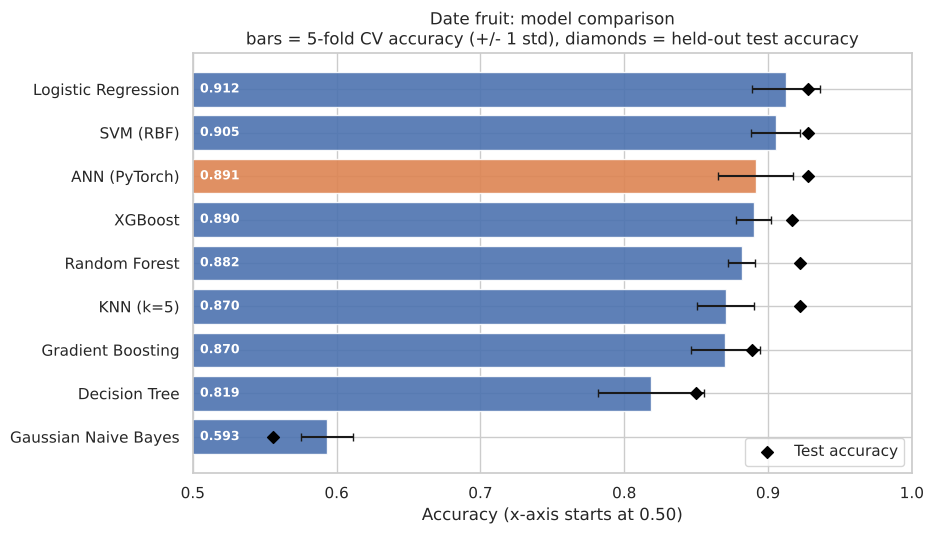

In [11]:
order = results.sort_values("CV Accuracy")
colors = ["#DD8452" if m.startswith("ANN") else "#4C72B0" for m in order["Model"]]
x_min = 0.50

fig, ax = plt.subplots(figsize=(9.5, 5.5))
ax.barh(order["Model"], order["CV Accuracy"], xerr=order["CV Acc Std"], color=colors, capsize=3, alpha=0.9)
ax.scatter(order["Test Accuracy"], order["Model"], marker="D", color="black", zorder=3, label="Test accuracy")
for y_pos, v in enumerate(order["CV Accuracy"]):
    ax.text(x_min + 0.005, y_pos, f"{v:.3f}", va="center", ha="left", color="white", fontsize=9, fontweight="bold")
ax.set_xlim(x_min, 1.0)
ax.set_title("Date fruit: model comparison\nbars = 5-fold CV accuracy (+/- 1 std), diamonds = held-out test accuracy")
ax.set_xlabel("Accuracy (x-axis starts at 0.50)")
ax.legend(loc="lower right")
plt.tight_layout()
save_fig("cls_model_comparison.png")
plt.show()

**How to read this:** bars show cross-validated accuracy with error bars (one standard deviation across folds). When two bars' error bars overlap, the difference between those models is **not** statistically meaningful on a dataset this small. Diamonds are the single held-out test score, which is noisier because the test set has only 180 samples (each sample is worth about 0.56 percentage points).

## 7. Error analysis: confusion matrices

Accuracy hides *which* classes get confused. Below are the confusion matrices (normalised by row, so each cell is the share of that true class) for the best model by cross-validation and for the ANN.

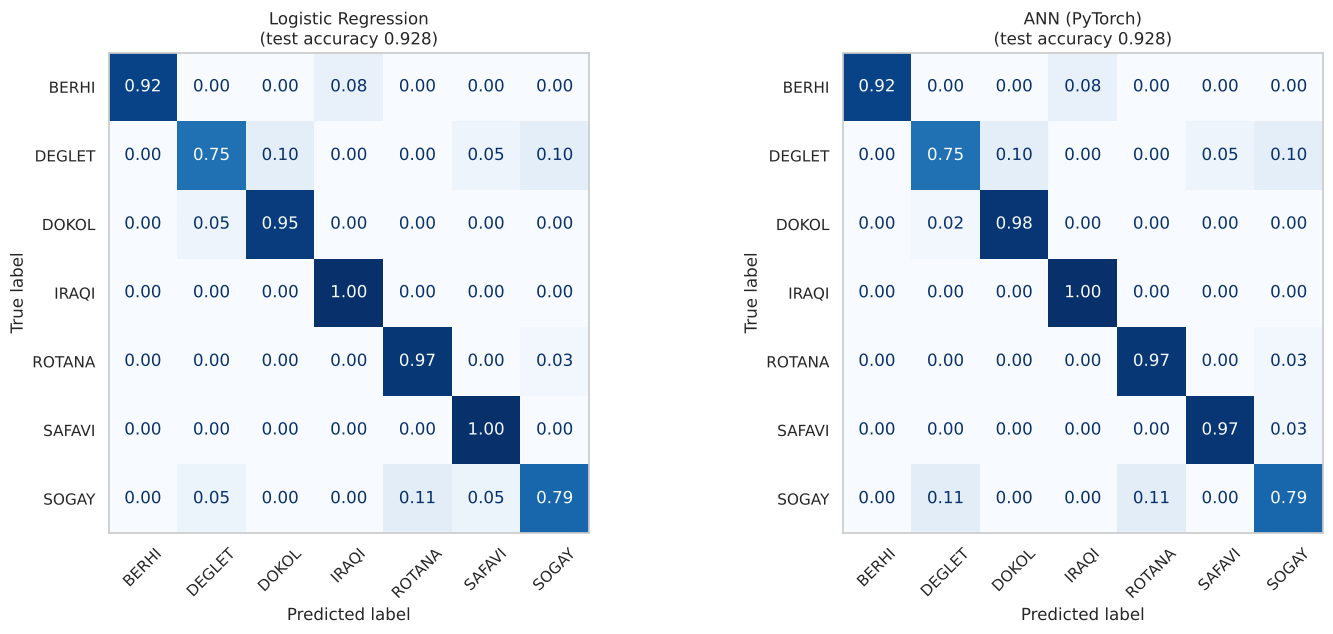

In [12]:
best_name = results.loc[1, "Model"]
ann_name = "ANN (PyTorch)"
show = [best_name] if best_name == ann_name else [best_name, ann_name]
if len(show) == 1:  # ANN is the best model: show the runner-up next to it
    show.append(results.loc[2, "Model"])

fig, axes = plt.subplots(1, len(show), figsize=(7.5 * len(show), 6.5))
for ax, name in zip(np.atleast_1d(axes), show):
    ConfusionMatrixDisplay.from_predictions(
        y_test, test_pred[name], display_labels=class_names,
        normalize="true", values_format=".2f", cmap="Blues", ax=ax, colorbar=False,
    )
    ax.set_title(f"{name}\n(test accuracy {accuracy_score(y_test, test_pred[name]):.3f})")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(False)
plt.tight_layout()
save_fig("cls_confusion_matrices.png")
plt.show()

In [13]:
for name in show:
    print("=" * 70)
    print(name)
    print("=" * 70)
    print(classification_report(y_test, test_pred[name], target_names=class_names, digits=3))

Logistic Regression
              precision    recall  f1-score   support

       BERHI      1.000     0.923     0.960        13
      DEGLET      0.833     0.750     0.789        20
       DOKOL      0.951     0.951     0.951        41
       IRAQI      0.933     1.000     0.966        14
      ROTANA      0.941     0.970     0.955        33
      SAFAVI      0.952     1.000     0.976        40
       SOGAY      0.833     0.789     0.811        19

    accuracy                          0.928       180
   macro avg      0.921     0.912     0.915       180
weighted avg      0.926     0.928     0.926       180

ANN (PyTorch)
              precision    recall  f1-score   support

       BERHI      1.000     0.923     0.960        13
      DEGLET      0.833     0.750     0.789        20
       DOKOL      0.952     0.976     0.964        41
       IRAQI      0.933     1.000     0.966        14
      ROTANA      0.941     0.970     0.955        33
      SAFAVI      0.975     0.975     0.975 

## 8. ANN deep dive

### 8.1 Training curves
These are the curves from the final ANN fit. The model keeps the weights from the epoch with the lowest validation loss (early stopping).

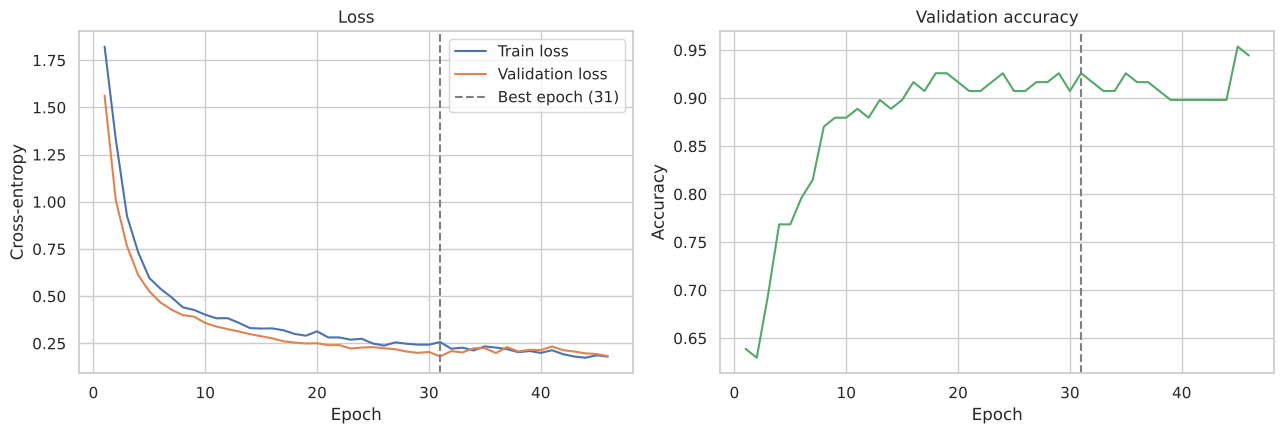

Training stopped after 46 epochs; best epoch = 31.


In [14]:
ann = fitted[ann_name].named_steps["model"]
hist = ann.history_
epochs = range(1, len(hist["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(epochs, hist["train_loss"], label="Train loss")
axes[0].plot(epochs, hist["val_loss"], label="Validation loss")
axes[0].axvline(ann.best_epoch_, color="gray", linestyle="--", label=f"Best epoch ({ann.best_epoch_})")
axes[0].set(title="Loss", xlabel="Epoch", ylabel="Cross-entropy")
axes[0].legend()

axes[1].plot(epochs, hist["val_acc"], color="#55A868")
axes[1].axvline(ann.best_epoch_, color="gray", linestyle="--")
axes[1].set(title="Validation accuracy", xlabel="Epoch", ylabel="Accuracy")
plt.tight_layout()
save_fig("cls_ann_training_curves.png")
plt.show()
print(f"Training stopped after {len(epochs)} epochs; best epoch = {ann.best_epoch_}.")

### 8.2 Seed stability
Neural networks depend on the random seed (weight initialisation, batch order, validation split). Here the ANN is retrained with 5 different seeds on the same training data and scored on the same test set.

In [15]:
seed_scores = []
for seed in range(5):
    m = scaled(TorchANNClassifier(random_state=seed))
    m.fit(X_train, y_train)
    seed_scores.append(accuracy_score(y_test, m.predict(X_test)))

seed_scores = np.array(seed_scores)
print("Test accuracy per seed:", np.round(seed_scores, 4))
print(f"Mean = {seed_scores.mean():.4f} | Std = {seed_scores.std():.4f} | Min = {seed_scores.min():.4f} | Max = {seed_scores.max():.4f}")

Test accuracy per seed: [0.9333 0.8889 0.9389 0.9333 0.95  ]
Mean = 0.9289 | Std = 0.0209 | Min = 0.8889 | Max = 0.9500


## 9. Save results

In [16]:
results.round(4).to_csv(os.path.join(RESULTS_DIR, "classification_results.csv"), index_label="Rank")
print("Saved:", os.path.join(RESULTS_DIR, "classification_results.csv"))
print("Figures:", sorted(os.listdir(FIG_DIR)))

Saved: ../results/classification_results.csv
Figures: ['cls_ann_training_curves.png', 'cls_class_distribution.png', 'cls_confusion_matrices.png', 'cls_model_comparison.png']


## 10. Conclusions

**1. The ANN did not beat the simple models on this dataset.**
Cross-validated accuracy: Logistic Regression 91.2 % (+/- 2.4), SVM 90.5 % (+/- 1.7), ANN 89.1 % (+/- 2.6), XGBoost 89.0 % (+/- 1.2). The error bars of these four overlap, so the honest reading is that they perform about the same, with a slight edge to the linear model. On the held-out test set, Logistic Regression, SVM and the ANN all score 92.8 % (167 of 180 samples).

**2. A linear model is already enough.**
Logistic Regression matching a neural network means the 34 features separate most classes almost linearly. With only 898 samples, extra model complexity has little to learn from. In a real project, Logistic Regression would be the pick here: it is as accurate, trains in milliseconds, and is easy to explain.

**3. A single ANN number is not reliable.**
Retraining the same ANN with 5 different seeds gave test accuracies between 88.9 % and 95.0 % (mean 92.9 %, std 2.1). Always report a mean over seeds or folds, not one lucky run.

**4. Some algorithms are clearly poorer fits.**
- **Gaussian Naive Bayes (59 %)** assumes features are independent, but many of these measurements (area, perimeter, axis lengths) are strongly correlated.
- **A single Decision Tree (82 %)** overfits. Ensembles of trees (Random Forest, XGBoost) recover roughly 6 to 7 points, but still stay below the linear model.

**5. The errors are concentrated in two varieties.**
BERHI, DOKOL, IRAQI, ROTANA and SAFAVI reach F1 of 0.95 or higher. **DEGLET and SOGAY** are the hard classes (F1 about 0.79 to 0.81 for both Logistic Regression and the ANN): DEGLET is confused with DOKOL and SOGAY, and SOGAY with ROTANA and DEGLET. Any future improvement should target these classes, for example with feature selection or additional features.

### Limitations

- The ANN uses 15 % of each training fold for early stopping, so it trains on slightly less data than the other models.
- No model was hyperparameter-tuned beyond sensible defaults. A tuned SVM, XGBoost or ANN could move up the ranking.
- The test set has 180 samples, so each sample is worth about 0.56 percentage points. Differences of 1 to 2 points on the test set are noise.

### Next steps

- Tune the top models with `GridSearchCV` or Optuna, using nested cross-validation.
- Try feature selection or dimensionality reduction (many features are highly correlated).
- Repeat the cross-validation with several seeds for tighter confidence intervals.
- Deploy the chosen model as a Streamlit app.